In [28]:
# importing the libraries

import numpy as np
import pandas as pd
import sklearn as sk
import matplotlib.pyplot as plt
import seaborn as sns


In [29]:
columns = ["age", "workclass","fnlwgt", "education", "education-num", "marital-status", "occupation",
           "relationship","race","sex","capital-gain","capital-loss","hours-per-week",
           "native-country","income"]
df = pd.read_csv(
    "../data/raw/adult.data",
    names=columns,
    header=None,
    skipinitialspace=True,
    na_values="?",
)
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [30]:
df.shape

(32561, 15)

In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       30725 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education-num   32561 non-null  int64
 5   marital-status  32561 non-null  str  
 6   occupation      30718 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital-gain    32561 non-null  int64
 11  capital-loss    32561 non-null  int64
 12  hours-per-week  32561 non-null  int64
 13  native-country  31978 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB


In [32]:
df.describe(include="all")

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
count,32561.000000,30725,3.256100e+04,32561,32561.000000,32561,30718,32561,32561,32561,32561.000000,32561.000000,32561.000000,31978,32561
unique,NaN,8,NaN,16,NaN,7,14,6,5,2,NaN,NaN,NaN,41,2
top,NaN,Private,NaN,HS-grad,NaN,Married-civ-spouse,Prof-specialty,Husband,White,Male,NaN,NaN,NaN,United-States,<=50K
freq,NaN,22696,NaN,10501,NaN,14976,4140,13193,27816,21790,NaN,NaN,NaN,29170,24720
mean,38.581647,NaN,1.897784e+05,NaN,10.080679,NaN,NaN,NaN,NaN,NaN,1077.648844,87.303830,40.437456,NaN,NaN
std,13.640433,NaN,1.055500e+05,NaN,2.572720,NaN,NaN,NaN,NaN,NaN,7385.292085,402.960219,12.347429,NaN,NaN
min,17.000000,NaN,1.228500e+04,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,1.000000,NaN,NaN
25%,28.000000,NaN,1.178270e+05,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
50%,37.000000,NaN,1.783560e+05,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
75%,48.000000,NaN,2.370510e+05,NaN,12.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,45.000000,NaN,NaN


In [33]:
# check for missing number

missing_summary = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().mean() * 100).round(2),
    'Data_Type': df.dtypes
})

missing_summary = missing_summary.sort_values(
    by='Missing_Percentage',
    ascending=False
)

display(missing_summary)

,Missing_Count,Missing_Percentage,Data_Type
occupation,1843,5.66,str
workclass,1836,5.64,str
native-country,583,1.79,str
fnlwgt,0,0.00,int64
education,0,0.00,str
education-num,0,0.00,int64
age,0,0.00,int64
marital-status,0,0.00,str
relationship,0,0.00,str
sex,0,0.00,str


In [34]:
# 1. what % of people earn <=50k?

df["income"].value_counts(normalize=True)


income
<=50K    0.75919
>50K     0.24081
Name: proportion, dtype: float64

In [35]:
# 76% earns less than r equals 50k. Only 24% earn above 50k

In [36]:
# 2. How many rows have capital-gain equals 99999?
(df["capital-gain"] == 99999).sum()


np.int64(159)

In [37]:
# 3. Do missing workclass and occupation happen on the same rows
df[df["workclass"].isna() & df["occupation"].isna()].shape[0]

1836

In [38]:
# Does missing data relate to income?
df.groupby(df["workclass"].isna())["income"].value_counts(normalize=True)

workclass  income
False      <=50K     0.751017
           >50K      0.248983
True       <=50K     0.895969
           >50K      0.104031
Name: proportion, dtype: float64

In [39]:
# what is the relationship between occupation, native-country and income
df.groupby(df["occupation"].isna())["income"].value_counts(normalize=True)

occupation  income
False       <=50K     0.750960
            >50K      0.249040
True        <=50K     0.896365
            >50K      0.103635
Name: proportion, dtype: float64

In [40]:
df.groupby(df["native-country"].isna())["income"].value_counts(normalize=True)

native-country  income
False           <=50K     0.759366
                >50K      0.240634
True            <=50K     0.749571
                >50K      0.250429
Name: proportion, dtype: float64

In [41]:
df["target"] = (df["income"] == ">50K").astype(int)

In [42]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'income', 'target'],
      dtype='str')

In [43]:
plot_df = df.copy()
cols = ["workclass", "occupation", "native-country"]
plot_df[cols] = plot_df[cols].fillna("unknown")

In [44]:
plot_df[["income", "target"]].head()
plot_df["target"].mean()

np.float64(0.2408095574460244)

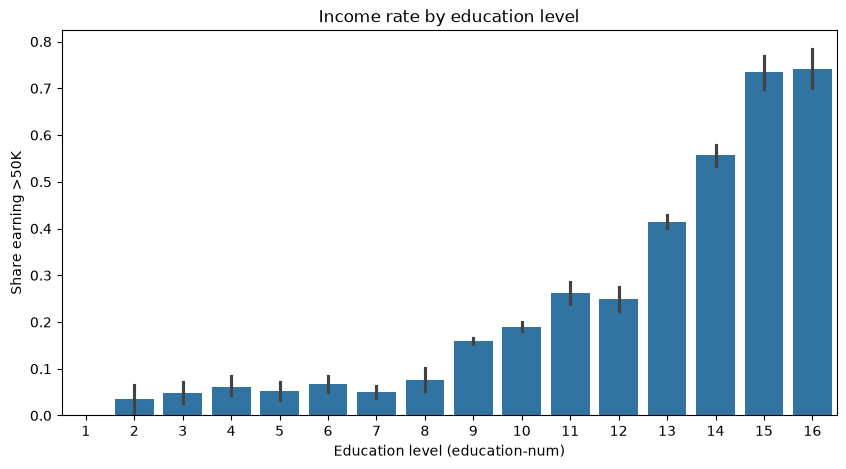

In [45]:
# 1. A bar chart of income rate by education-num.

plt.figure(figsize=(10, 5))
sns.barplot(data=df, x="education-num", y="target")
plt.ylabel("Share earning >50K")
plt.xlabel("Education level (education-num)")
plt.title("Income rate by education level")
plt.show()

In [46]:
# Income rate increases with education, slowly at first and steeply after a bachelor’s degree.

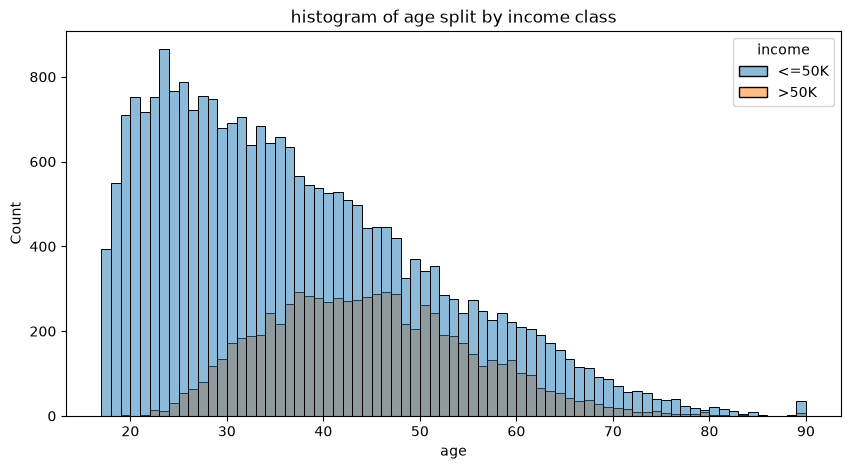

In [47]:
# 2. A histogram of age, split by income class. Use sns.histplot(data=df, x="age", hue="income").

plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="age", hue="income", binwidth=1)
plt.title("histogram of age split by income class")
plt.show()

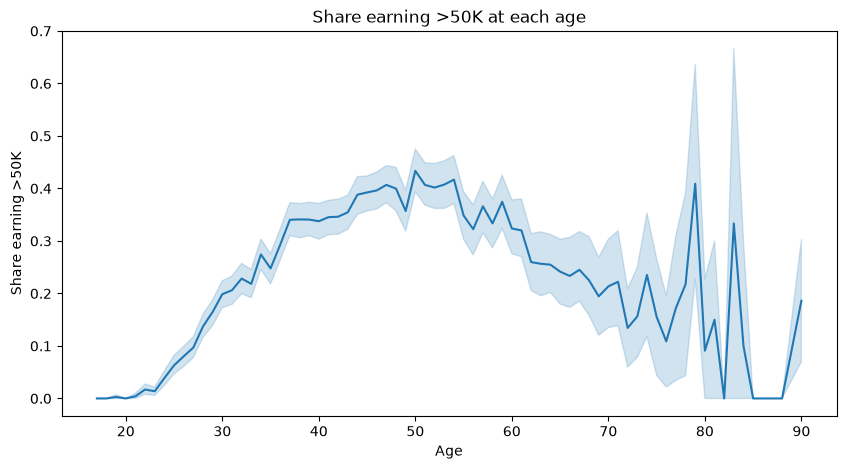

In [48]:
# Make the chart area 10 wide and 5 tall
plt.figure(figsize=(10, 5))

# For every age on the x axis, draw the share of people who earn >50K.
# "target" is 1 for >50K and 0 otherwise, so its average IS that share.
sns.lineplot(data=df, x="age", y="target")

plt.title("Share earning >50K at each age")
plt.xlabel("Age")
plt.ylabel("Share earning >50K")
plt.show()

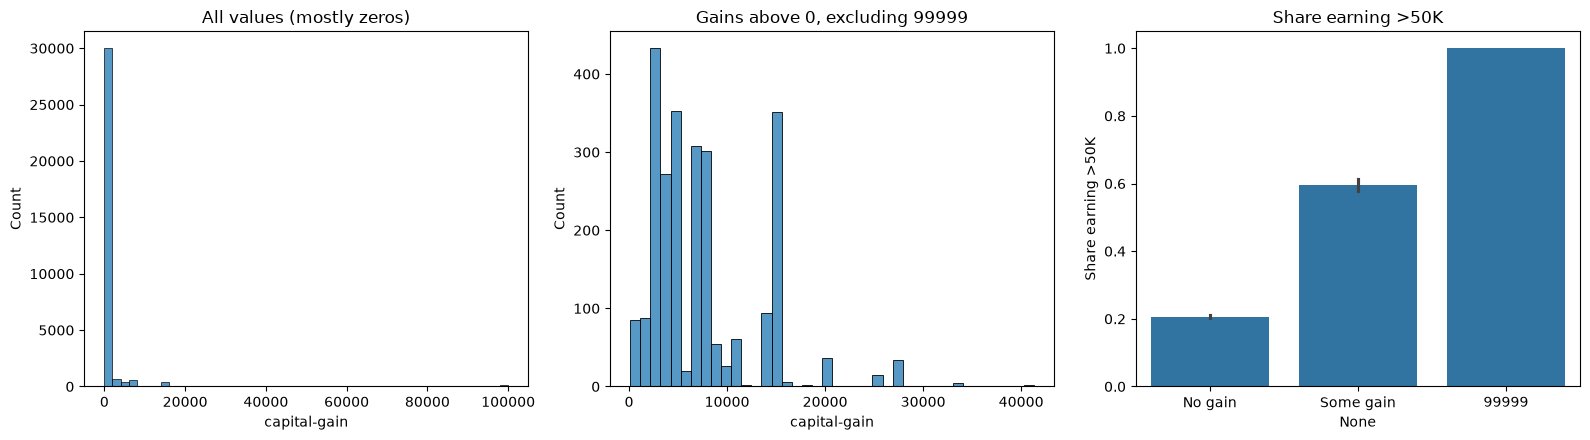

In [49]:
# capital gains, with and without zero

# Make 3 charts side by side
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

# Chart 1: ALL values.
sns.histplot(df["capital-gain"], bins=50, ax=ax[0])
ax[0].set_title("All values (mostly zeros)")

# Chart 2: only people who HAVE a gain, leaving out 0 and the 99999 cap.
# "&" means "and" - both conditions must be true.
has_gain = df[(df["capital-gain"] > 0) & (df["capital-gain"] < 99999)]
sns.histplot(has_gain["capital-gain"], bins=40, ax=ax[1])
ax[1].set_title("Gains above 0, excluding 99999")

# Chart 3: income rate for three groups: no gain, some gain, and exactly 99999.
group = pd.Series(
    np.where(df["capital-gain"] == 0, "No gain",
    np.where(df["capital-gain"] == 99999, "99999", "Some gain")),
    index=df.index)
sns.barplot(x=group, y=df["target"], order=["No gain", "Some gain", "99999"], ax=ax[2])
ax[2].set_title("Share earning >50K")
ax[2].set_ylabel("Share earning >50K")

plt.tight_layout()
plt.show()

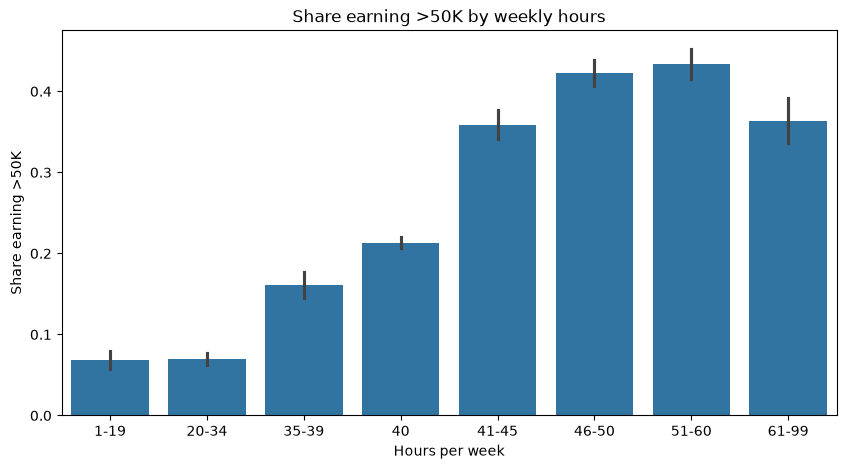

,mean,size
hours_band,,
1-19,0.068662,1704
20-34,0.069606,3879
35-39,0.161009,2180
40,0.213380,15217
41-45,0.358313,2442
46-50,0.422483,3496
51-60,0.434268,2533
61-99,0.363964,1110


In [50]:
# Group hours into bands. "bins" are the cut points, "labels" the names.
bins   = [0, 19, 34, 39, 40, 45, 50, 60, 100]
labels = ["1-19", "20-34", "35-39", "40", "41-45", "46-50", "51-60", "61-99"]
df["hours_band"] = pd.cut(df["hours-per-week"], bins=bins, labels=labels)

# Draw the share earning >50K in each band
plt.figure(figsize=(10, 5))
sns.barplot(data=df, x="hours_band", y="target")
plt.title("Share earning >50K by weekly hours")
plt.xlabel("Hours per week")
plt.ylabel("Share earning >50K")
plt.show()

# Show how many people are in each band, plus the share
df.groupby("hours_band", observed=True)["target"].agg(["mean", "size"])

In [51]:
#Share earning over 50K increases with hours up to about 60 hours per week, then drops slightly, though 61+ has only 1,110 people, 
# so that dip is less certain.

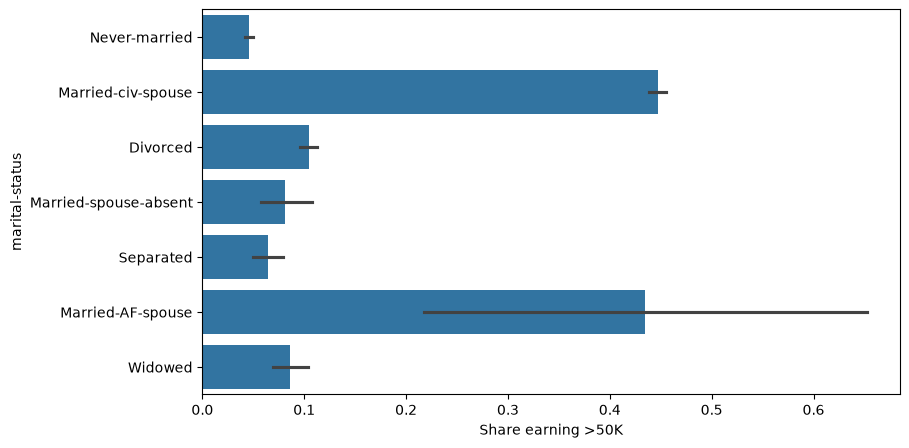

In [52]:
# plot of marital-status and earning above 50k

plt.figure(figsize=(9, 5))
sns.barplot(data=df, y="marital-status", x="target")
plt.xlabel("Share earning >50K")
plt.show()

In [53]:
# the highest percentage of earners >50k is "married-civ-spouse" while the lowest on the list been "Never-married"

# EDA Summary: UCI Adult Income (training file, 32,561 rows)

## Key findings and decisions

| # | Finding | Evidence | Decision |
|---|---|---|---|
| 1 | **Target is imbalanced** | 76% earn `<=50K`, 24% earn `>50K` | Don't use accuracy. Use PR-AUC, F1 and recall. Handle imbalance with class weights, not oversampling before the split. |
| 2 | **Missing values are in three text columns** | `workclass` 5.6%, `occupation` 5.7%, `native-country` 1.8% | Handle inside the pipeline, after the train/test split. |
| 3 | **Missing `workclass` and `occupation` carry information** | Same rows are missing both. Only 10.4% of them earn >50K, against 24.9% for the rest. | Don't drop or fill with the most common value. Use an `Unknown` category. |
| 4 | **Missing `native-country` looks random** | 25.0% earn >50K when missing vs 24.1% when present | `Unknown` category is harmless. |
| 5 | **`capital-gain` is heavily right-skewed** | 92% of values are 0. Any gain: 62% earn >50K. No gain: 21%. | Add a `has_gain` flag. Use log transform for linear models. Trees need no change. |
| 6 | **99999 is a Census top-code, not a real amount** | 159 rows, all earn >50K | Keep the rows. Add an `is_top_coded` flag. Note that it is a perfect predictor in this dataset only. |
| 7 | **Education raises the >50K rate, non-linearly** | About 5% below level 9, about 74% at levels 15-16 | Tree models should capture this well. |
| 8 | **Age has a curved relationship with income** | Share earning >50K peaks around age 50 (about 43%) | Trees handle it. Linear models need age bands. |
| 9 | **Hours per week matters** | 7% under 35 hours, 21% at 40, 42-43% at 46-60 | Keep as a feature. Consider bands. |
| 10 | **Marital status matters, partly because of age** | Married-civ-spouse 44.7% vs Never-married 4.6%. Among ages 35-45: 51% vs 13%. | Keep. Check overlap with `relationship`. |

## Data-quality notes
- `adult.test` has a junk first line and labels ending in `.` (e.g. `>50K.`). These must be fixed before evaluating.
- `Married-AF-spouse` has only 23 people, so its rate (43.5%) is unreliable.
- `age` is top-coded at 90.
- `fnlwgt` is a survey weight, and `education` duplicates `education-num`. Both are candidates to drop.
- `sex` and `race` are protected attributes. Exclude them from the model and audit fairness separately.
- Associations here are not causal. For example, part of the marital-status effect is explained by age.

## Next step
Split first, then build a preprocessing pipeline (fit on training data only), then compare models using cross-validation.


In [ ]:
git add .
git commit -m "docs: add EDA findings summary"
git push